In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from pathlib import Path

fig_dir = Path("/home/tlanghorst_umass_edu/cee-water/swot-ml/notebooks/multigraph_manual/tests/figures")

results = pd.read_parquet('/nas/cee-water/cjgleason/ted/swot-ml/notebooks/multigraph_manual/tests/reach_parameter_results.parquet')

In [2]:
results

,subbasin,Q_obs,Q_hat,A0,n,h,w,s
0,BRANA-14215000,288.883972,216.217285,191.089569,0.032532,1.5993,23.617023,0.000046
1,BRANA-14215000,224.160049,207.862335,191.089569,0.032532,0.7349,28.699423,0.000071
2,BRANA-14215000,111.683998,170.494476,191.089569,0.032532,0.0148,27.709641,0.000064
3,BRANA-14215000,129.034988,55.391499,191.089569,0.032532,-1.9966,37.799126,0.000055
4,BRANA-14215000,159.897064,261.171753,191.089569,0.032532,0.8438,19.838108,0.000073
...,...,...,...,...,...,...,...,...
45089,BRANA-46902000,137.731964,112.764061,157.212494,0.024049,-0.3885,47.599998,0.000092
45090,BRANA-46902000,196.785065,158.306656,157.212494,0.024049,0.3494,53.919369,0.000097
45091,BRANA-46902000,195.704010,185.938934,157.212494,0.024049,0.3616,44.313126,0.000108
45092,BRANA-46902000,268.534119,185.379944,157.212494,0.024049,0.8825,62.864399,0.000087


In [3]:
def get_modified_z_score(group):
    median = group.median()
    mad = (group - median).abs().median()
    
    if mad == 0:
        return pd.Series(0, index=group.index)
        
    modified_z = 0.6745 * (group - median) / mad
    return modified_z.abs()

# Apply calculation to each subbasin group
results['dA'] = results['h'] * results['w']
z_scores = results.groupby('subbasin')['w'].transform(get_modified_z_score)

mask = z_scores < 3.0
results = results[mask]


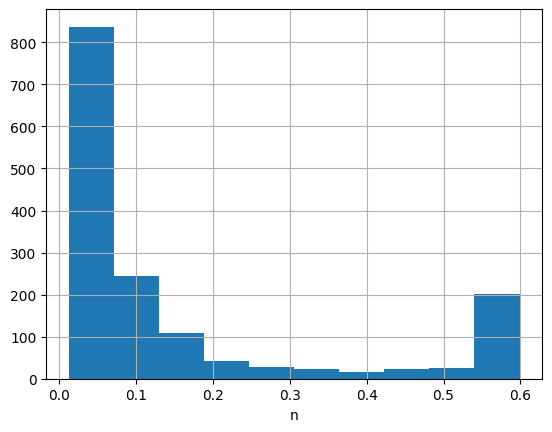

In [4]:
basin_med = results.groupby('subbasin').apply('median')

basin_med['n'].hist()
plt.xlabel('n')
plt.savefig(fig_dir / 'n_dist.png', dpi=300)

In [8]:
basin_med

,Q_obs,Q_hat,A0,n,h,w,s,dA
subbasin,,,,,,,,
ABOM-123774010,9.059001,5.936117,33.021862,0.051942,-0.03965,65.640228,0.000199,-2.285355
ABOM-128547010,73.174496,87.708031,149.547699,0.042629,0.07325,136.144249,0.000503,9.382675
ABOM-132966010,13.260002,15.241202,43.146572,0.073712,0.07580,63.204830,0.000908,3.462995
ABOM-133073010,27.234005,25.982891,57.244087,0.077509,-0.01150,60.645466,0.001229,-0.611501
ABOM-133975010,12.532000,16.002697,43.634296,0.071371,0.07580,63.204830,0.000908,3.462995
...,...,...,...,...,...,...,...,...
USGS-15565447,11043.571289,9787.966797,18336.087891,0.050344,0.15840,1781.826416,0.000036,285.934326
USGS-15580095,80.844597,56.252352,152.884476,0.063603,-0.13285,135.331772,0.000666,-18.588388
USGS-15744500,457.317230,607.773254,1320.253662,0.038672,-0.04470,441.951584,0.000084,-19.778780


In [11]:
from evaluate import metrics

def get_nse(grp):
    y = grp['Q_obs']
    y_pred = grp['Q_hat']

    nse = metrics.calc_nse(y, y_pred)
    kge_results = metrics.calc_kge(y, y_pred)
    if isinstance(kge_results, tuple):
        kge, corr, alpha, beta = kge_results
    else:
        kge = corr = alpha = beta = np.nan
    out = {
        'nse': nse,
        'kge': kge,
        'corr': corr,
        'alpha': alpha,
        'beta': beta
    }
    return pd.Series(out)
    
kge = results.groupby('subbasin').apply(get_nse, include_groups=False).dropna().sort_values('kge')
kge = kge.join(basin_med)
kge

,nse,kge,corr,alpha,beta,Q_obs,Q_hat,A0,n,h,w,s,dA
subbasin,,,,,,,,,,,,,
USGS-04152049,-53022.816406,-139.623805,0.300772,129.895706,57.217991,2.708507,152.554123,286.847626,0.599000,2.90930,66.087976,0.001995,167.035767
EAUF-V7144010,-13505.054688,-105.301991,0.169249,55.265656,92.403839,5.884000,895.739746,1215.762207,0.599000,0.13115,68.145737,0.004446,9.626161
USGS-01199050,-1098.128296,-28.791920,0.683605,24.624496,19.147770,2.010496,32.825031,92.759529,0.599000,1.11680,61.197971,0.003816,57.035824
UKEA-4180TH,-266.040741,-11.149416,0.142133,12.631306,4.403691,2.667000,5.318225,531.803162,0.599000,-1.08990,221.558441,0.000080,-233.756226
USGS-14335072,-382.399689,-10.845457,0.067657,7.439116,10.898655,36.953487,442.837463,810.917175,0.599000,0.11300,65.313976,0.003414,6.847552
...,...,...,...,...,...,...,...,...,...,...,...,...,...
USGS-05378500,0.985988,0.974194,0.993644,1.015172,1.019884,872.159210,902.103912,4044.649170,0.062707,0.13750,769.338928,0.000018,100.082474
USGS-15129120,0.976897,0.974745,0.988880,1.010703,1.019991,798.535156,779.127625,871.823853,0.052348,-0.10740,419.977386,0.001146,-45.751205
BRANA-56994500,0.972174,0.978016,0.986523,1.007926,0.984545,451.879150,478.082977,806.858887,0.046465,0.26835,521.945099,0.000245,139.633804


In [12]:
kge

,nse,kge,corr,alpha,beta,Q_obs,Q_hat,A0,n,h,w,s,dA
subbasin,,,,,,,,,,,,,
USGS-04152049,-53022.816406,-139.623805,0.300772,129.895706,57.217991,2.708507,152.554123,286.847626,0.599000,2.90930,66.087976,0.001995,167.035767
EAUF-V7144010,-13505.054688,-105.301991,0.169249,55.265656,92.403839,5.884000,895.739746,1215.762207,0.599000,0.13115,68.145737,0.004446,9.626161
USGS-01199050,-1098.128296,-28.791920,0.683605,24.624496,19.147770,2.010496,32.825031,92.759529,0.599000,1.11680,61.197971,0.003816,57.035824
UKEA-4180TH,-266.040741,-11.149416,0.142133,12.631306,4.403691,2.667000,5.318225,531.803162,0.599000,-1.08990,221.558441,0.000080,-233.756226
USGS-14335072,-382.399689,-10.845457,0.067657,7.439116,10.898655,36.953487,442.837463,810.917175,0.599000,0.11300,65.313976,0.003414,6.847552
...,...,...,...,...,...,...,...,...,...,...,...,...,...
USGS-05378500,0.985988,0.974194,0.993644,1.015172,1.019884,872.159210,902.103912,4044.649170,0.062707,0.13750,769.338928,0.000018,100.082474
USGS-15129120,0.976897,0.974745,0.988880,1.010703,1.019991,798.535156,779.127625,871.823853,0.052348,-0.10740,419.977386,0.001146,-45.751205
BRANA-56994500,0.972174,0.978016,0.986523,1.007926,0.984545,451.879150,478.082977,806.858887,0.046465,0.26835,521.945099,0.000245,139.633804


In [17]:
kge = kge[kge['n']<0.59]
kge

,nse,kge,corr,alpha,beta,Q_obs,Q_hat,A0,n,h,w,s,dA
subbasin,,,,,,,,,,,,,
USGS-14144700,-23.252487,-3.014181,0.114422,4.912889,1.136732,3794.456543,3366.770752,10872.306641,0.055262,0.04090,985.495361,0.000011,43.476269
ABOM-166743010,-20.686382,-2.859215,0.242917,4.780421,1.169669,5.205000,3.308437,90.342567,0.584451,-0.12905,99.016361,0.000349,-8.767963
BRANA-17091000,-25.584181,-1.834705,0.056306,3.662869,0.767366,117.304977,80.548729,89.203941,0.052127,-0.12660,36.464375,0.001039,-3.738689
USGS-07381490,-8.838196,-1.291473,0.171303,3.123013,1.238595,3794.456543,3645.305908,4169.910645,0.027413,0.75320,494.619232,0.000026,339.875183
EAUF-O0554010,-9.599558,-1.214661,-0.075971,2.923743,1.214986,1.633000,1.715540,31.284639,0.586731,-0.00010,56.599152,0.002048,-0.006041
...,...,...,...,...,...,...,...,...,...,...,...,...,...
USGS-05378500,0.985988,0.974194,0.993644,1.015172,1.019884,872.159210,902.103912,4044.649170,0.062707,0.13750,769.338928,0.000018,100.082474
USGS-15129120,0.976897,0.974745,0.988880,1.010703,1.019991,798.535156,779.127625,871.823853,0.052348,-0.10740,419.977386,0.001146,-45.751205
BRANA-56994500,0.972174,0.978016,0.986523,1.007926,0.984545,451.879150,478.082977,806.858887,0.046465,0.26835,521.945099,0.000245,139.633804


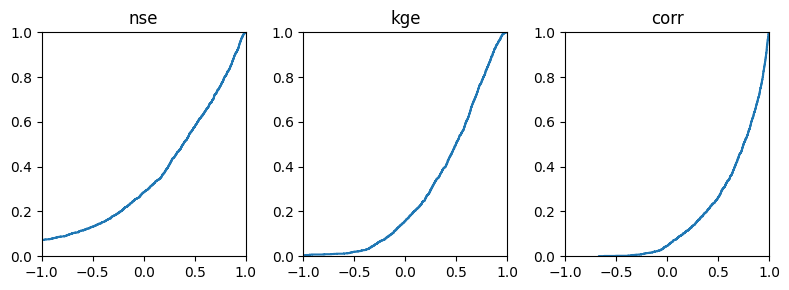

In [18]:
fig, axes = plt.subplots(1,3, figsize=(8,3))
lims = [(-1,1), (-1,1), (-1, 1)]#, (0, 2), (0, 2)]
for c, ax, lim in zip(kge.columns, axes, lims):
    y = kge[c]
    ax.ecdf(y)
    ax.set_xlim(lim)
    ax.set_title(c)

fig.tight_layout()
fig.savefig(fig_dir / 'cdfs.png', dpi=300)

In [20]:
kge.iloc[:20]

,nse,kge,corr,alpha,beta,Q_obs,Q_hat,A0,n,h,w,s,dA
subbasin,,,,,,,,,,,,,
USGS-14144700,-23.252487,-3.014181,0.114422,4.912889,1.136732,3794.456543,3366.770752,10872.306641,0.055262,4.090000e-02,985.495361,0.000011,4.347627e+01
ABOM-166743010,-20.686382,-2.859215,0.242917,4.780421,1.169669,5.205000,3.308437,90.342567,0.584451,-1.290500e-01,99.016361,0.000349,-8.767963e+00
BRANA-17091000,-25.584181,-1.834705,0.056306,3.662869,0.767366,117.304977,80.548729,89.203941,0.052127,-1.266000e-01,36.464375,0.001039,-3.738689e+00
USGS-07381490,-8.838196,-1.291473,0.171303,3.123013,1.238595,3794.456543,3645.305908,4169.910645,0.027413,7.532000e-01,494.619232,0.000026,3.398752e+02
EAUF-O0554010,-9.599558,-1.214661,-0.075971,2.923743,1.214986,1.633000,1.715540,31.284639,0.586731,-1.000000e-04,56.599152,0.002048,-6.040753e-03
ECCC-02OJ007,-10.236316,-1.195908,-0.254398,2.780991,0.723293,466.766479,217.520065,1476.214722,0.078877,1.108500e-01,439.959946,0.000022,4.866652e+01
USGS-08401500,-8.273793,-1.103362,-0.669234,2.277696,1.072681,4.941290,3.694602,83.304504,0.528207,-3.038000e-01,62.175564,0.000859,-1.998377e+01
USGS-01354500,-7.692280,-0.972256,-0.339948,2.444072,1.094819,136.345627,93.716518,688.553223,0.035593,-7.650000e-02,247.326462,0.000009,-1.743987e+01
USGS-02323000,-7.423736,-0.941303,-0.135110,2.566595,0.838868,385.109314,200.114929,611.007385,0.112745,4.077000e-01,87.826950,0.000065,2.153799e+01


<Axes: xlabel='Q_obs', ylabel='Q_hat'>

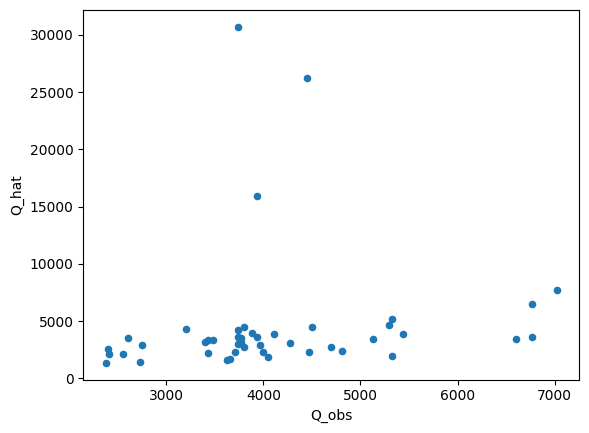

In [21]:
basin_results = results[results['subbasin'] == 'USGS-14144700']
basin_results.plot.scatter('Q_obs','Q_hat')

<Axes: xlabel='Q_obs', ylabel='h'>

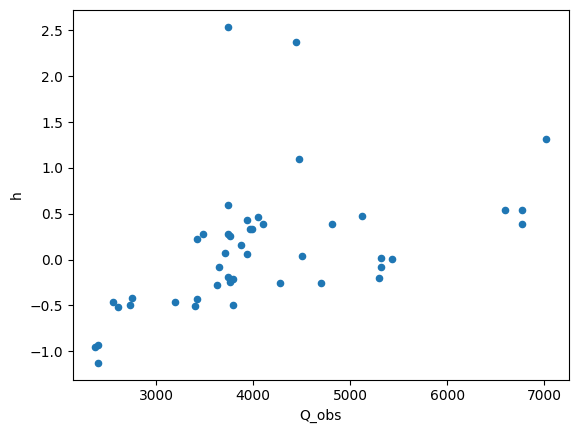

In [22]:
basin_results.plot.scatter('Q_obs','h')

In [21]:
basin_results

,subbasin,Q_obs,Q_hat,A0,n,h,w,s,dA
32433,USGS-04152049,1.860417,287.394653,286.847626,0.599,7.8218,51.136189,0.001968,399.977051
32434,USGS-04152049,2.653289,169.232407,286.847626,0.599,3.4799,55.419834,0.002513,192.855469
32435,USGS-04152049,2.288001,2.532896,286.847626,0.599,-2.6474,85.425026,0.000986,-226.154205
32436,USGS-04152049,3.199804,48.510529,286.847626,0.599,-0.5170,62.817463,0.002022,-32.476631
32437,USGS-04152049,4.190894,292.188507,286.847626,0.599,6.1180,75.609100,0.002562,462.576477
32438,USGS-04152049,4.445745,249.258041,286.847626,0.599,8.3193,59.222881,0.001180,492.692902
32439,USGS-04152049,2.687269,277.992950,286.847626,0.599,8.2441,69.358490,0.001313,571.798279
32440,USGS-04152049,6.767726,0.000000,286.847626,0.599,-3.5818,80.084770,0.000068,-286.847626
32441,USGS-04152049,2.729744,26.980671,286.847626,0.599,-1.1612,84.770325,0.002537,-98.435303
32442,USGS-04152049,1.985011,135.875839,286.847626,0.599,2.3387,60.382282,0.002655,141.216049
